***CLEANING PREPROCESSE***

In [27]:
import pandas as pd
import re
import html
from google.colab import files

uploaded = files.upload()

Saving raw_tweets_uts.csv to raw_tweets_uts (1).csv


In [28]:
#membaca data
nama_file = next(iter(uploaded))
data = pd.read_csv(nama_file)

print("Ukuran data awal:", data.shape)
display(data.head())
print("\nKolom:", data.columns.tolist())

Ukuran data awal: (898, 15)


,conversation_id_str,created_at,favorite_count,full_text,id_str,image_url,in_reply_to_screen_name,lang,location,quote_count,reply_count,retweet_count,tweet_url,user_id_str,username
0,1825837809124688181,Tue Aug 20 10:10:30 +0000 2024,22,[cm] Guys kalian ada yang pake ChatGPT ga ya b...,1825837809124688181,NaN,NaN,in,NaN,1,41,3,https://x.com/collegemfs/status/18258378091246...,1204013052468875265,collegemfs
1,2050529721474236502,Sat May 02 10:55:57 +0000 2026,2,#zonauang ad yg jual claude ai pro kah?? team ...,2050529721474236502,NaN,NaN,in,NaN,1,14,0,https://x.com/flocallings/status/2050529721474...,1993683251760914432,flocallings
2,2046917650429915273,Wed Apr 22 11:42:52 +0000 2026,80,[cm] haii aku sedang butuh partisipan untuk uj...,2046917650429915273,https://pbs.twimg.com/media/HGgcwQ-aEAASH5Y.jpg,NaN,in,NaN,3,54,8,https://x.com/collegemfs/status/20469176504299...,1204013052468875265,collegemfs
3,2109345101810155538,Sun Oct 11 18:07:16 +0000 2026,0,my setup back in 2021. my first year in uni. l...,2109345101810155538,https://pbs.twimg.com/media/HUXlAQcWwAADowJ.jpg,NaN,en,NaN,0,1,0,https://x.com/BriannOtieno/status/210934510181...,1434865333588877312,BriannOtieno
4,1909087314585747464,Mon Apr 07 03:34:19 +0000 2025,1,Gimana rasanya sekolah/kuliah di era Chatgpt ?,1909087314585747464,NaN,NaN,id,NaN,0,5,0,https://x.com/RanBetterRan/status/190908731458...,1299994386466365440,RanBetterRan



Kolom: ['conversation_id_str', 'created_at', 'favorite_count', 'full_text', 'id_str', 'image_url', 'in_reply_to_screen_name', 'lang', 'location', 'quote_count', 'reply_count', 'retweet_count', 'tweet_url', 'user_id_str', 'username']


In [29]:
#membuat kolom standar baru tanpa menghapus kolom aslinya.
data["text"] = data["full_text"].fillna("").astype(str).str.strip()

data["created_at"] = pd.to_datetime(
    data["created_at"],
    errors="coerce",
    utc=True
)

data["like_count"] = pd.to_numeric(
    data["favorite_count"],
    errors="coerce"
)

/tmp/ipykernel_2752/3258551481.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data["created_at"] = pd.to_datetime(


In [30]:
#memeriksa kualitas data.
print("Jumlah data:", len(data))
print("Teks kosong:", data["text"].eq("").sum())
print("Tanggal tidak terbaca:", data["created_at"].isna().sum())
print("Likes kosong:", data["like_count"].isna().sum())
print("Likes negatif:", (data["like_count"] < 0).sum())

Jumlah data: 898
Teks kosong: 0
Tanggal tidak terbaca: 0
Likes kosong: 0
Likes negatif: 0


In [31]:
#menghapus baris yang teksnya kosong serta baris dengan jumlah likes yang hilang, tidak valid, atau negatif.
data = data[data["text"].ne("")].copy()

data = data[
    data["like_count"].notna() &
    data["like_count"].ge(0)
].copy()

In [32]:
#menghapus postingan yang tercatat lebih dari satu kali.
if "id_str" in data.columns:
    data = data.drop_duplicates(
        subset=["id_str"],
        keep="first"
    )

In [33]:
#memeriksa kesamaan isi teks
def normalisasi_duplikat(teks):
    teks = html.unescape(str(teks)).lower()
    teks = re.sub(r"\s+", " ", teks).strip()
    return teks

data["_kunci_teks"] = data["text"].apply(
    normalisasi_duplikat
)

data = data.drop_duplicates(
    subset=["_kunci_teks"],
    keep="first"
).copy()

data = data.drop(columns=["_kunci_teks"])

In [34]:
def cleansing(teks):
    teks = html.unescape(str(teks))
    teks = teks.lower()

    # Menghapus URL
    teks = re.sub(
        r"https?://\S+|www\.\S+",
        " ",
        teks
    )

    # Menghapus mention
    teks = re.sub(
        r"@\w+",
        " ",
        teks
    )

    # Mempertahankan kata dalam hashtag
    teks = re.sub(
        r"#([A-Za-z0-9_]+)",
        r" \1 ",
        teks
    )

    # Menghapus tanda baca dan simbol
    teks = re.sub(
        r"[^\w\s]",
        " ",
        teks
    )

    # Merapikan spasi
    teks = re.sub(
        r"\s+",
        " ",
        teks
    ).strip()

    return teks

In [35]:
#terapkan fungsi tersebut pada kolom text
data["cleaned_text"] = data["text"].apply(cleansing)

display(
    data[["text", "cleaned_text"]].head(10)
)

,text,cleaned_text
0,[cm] Guys kalian ada yang pake ChatGPT ga ya b...,cm guys kalian ada yang pake chatgpt ga ya bua...
1,#zonauang ad yg jual claude ai pro kah?? team ...,zonauang ad yg jual claude ai pro kah team mun...
2,[cm] haii aku sedang butuh partisipan untuk uj...,cm haii aku sedang butuh partisipan untuk uji ...
3,my setup back in 2021. my first year in uni. l...,my setup back in 2021 my first year in uni lif...
4,Gimana rasanya sekolah/kuliah di era Chatgpt ?,gimana rasanya sekolah kuliah di era chatgpt
5,Halo semua ada yang mau barter kuesioner? Aku ...,halo semua ada yang mau barter kuesioner aku m...
6,[cm] Kalian pernah curhat ke AI (ChatGPT Meta ...,cm kalian pernah curhat ke ai chatgpt meta dll...
8,Kuliah 2 jam dari Stanford University ini meng...,kuliah 2 jam dari stanford university ini meng...
9,stop kuliah modal chatgpt dan drilling nilai d...,stop kuliah modal chatgpt dan drilling nilai d...
10,buat yang masih kuliah ini worth it banget sih...,buat yang masih kuliah ini worth it banget sih...


In [36]:
#Menghitung jumlah kata dan hashtag
data["word_count"] = data["text"].apply(
    lambda teks: len(
        re.findall(r"\b\w+\b", str(teks))
    )
)

data["hashtag_count"] = data["text"].apply(
    lambda teks: len(
        re.findall(r"(?<!\w)#\w+", str(teks))
    )
)

In [37]:
# Memastikan tipe data tanggal tetap datetime
data["created_at"] = pd.to_datetime(
    data["created_at"],
    errors="coerce",
    utc=True
)

# Menyimpan dataset hasil cleaning
data.to_csv(
    "tweets_cleaned_preprocessed.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Cleaning dan preprocessing berhasil!")
print("Jumlah data akhir:", len(data))

display(data.head())

Cleaning dan preprocessing berhasil!
Jumlah data akhir: 891


,conversation_id_str,created_at,favorite_count,full_text,id_str,image_url,in_reply_to_screen_name,lang,location,quote_count,reply_count,retweet_count,tweet_url,user_id_str,username,text,like_count,cleaned_text,word_count,hashtag_count
0,1825837809124688181,2024-08-20 10:10:30+00:00,22,[cm] Guys kalian ada yang pake ChatGPT ga ya b...,1825837809124688181,NaN,NaN,in,NaN,1,41,3,https://x.com/collegemfs/status/18258378091246...,1204013052468875265,collegemfs,[cm] Guys kalian ada yang pake ChatGPT ga ya b...,22,cm guys kalian ada yang pake chatgpt ga ya bua...,41,0
1,2050529721474236502,2026-05-02 10:55:57+00:00,2,#zonauang ad yg jual claude ai pro kah?? team ...,2050529721474236502,NaN,NaN,in,NaN,1,14,0,https://x.com/flocallings/status/2050529721474...,1993683251760914432,flocallings,#zonauang ad yg jual claude ai pro kah?? team ...,2,zonauang ad yg jual claude ai pro kah team mun...,23,1
2,2046917650429915273,2026-04-22 11:42:52+00:00,80,[cm] haii aku sedang butuh partisipan untuk uj...,2046917650429915273,https://pbs.twimg.com/media/HGgcwQ-aEAASH5Y.jpg,NaN,in,NaN,3,54,8,https://x.com/collegemfs/status/20469176504299...,1204013052468875265,collegemfs,[cm] haii aku sedang butuh partisipan untuk uj...,80,cm haii aku sedang butuh partisipan untuk uji ...,48,0
3,2109345101810155538,2026-10-11 18:07:16+00:00,0,my setup back in 2021. my first year in uni. l...,2109345101810155538,https://pbs.twimg.com/media/HUXlAQcWwAADowJ.jpg,NaN,en,NaN,0,1,0,https://x.com/BriannOtieno/status/210934510181...,1434865333588877312,BriannOtieno,my setup back in 2021. my first year in uni. l...,0,my setup back in 2021 my first year in uni lif...,27,0
4,1909087314585747464,2025-04-07 03:34:19+00:00,1,Gimana rasanya sekolah/kuliah di era Chatgpt ?,1909087314585747464,NaN,NaN,id,NaN,0,5,0,https://x.com/RanBetterRan/status/190908731458...,1299994386466365440,RanBetterRan,Gimana rasanya sekolah/kuliah di era Chatgpt ?,1,gimana rasanya sekolah kuliah di era chatgpt,7,0


In [38]:
from google.colab import files

files.download("tweets_cleaned_preprocessed.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**CLUSTERING**


In [39]:
# CLUSTERING DATA TEKS MENGGUNAKAN TF-IDF DAN K-MEANS

import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans

In [40]:
# Mengambil teks yang sudah dibersihkan
teks_cluster = data['cleaned_text'].fillna('').astype(str)

# Mengubah teks menjadi fitur TF-IDF
vectorizer = TfidfVectorizer(max_features=1000)
X_tfidf = vectorizer.fit_transform(teks_cluster)

print("Jumlah data:", X_tfidf.shape[0])
print("Jumlah fitur TF-IDF:", X_tfidf.shape[1])

# Membentuk 3 cluster
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

data['cluster'] = kmeans.fit_predict(X_tfidf)
print("\nJumlah data pada setiap cluster:")
print(data['cluster'].value_counts().sort_index())

Jumlah data: 891
Jumlah fitur TF-IDF: 1000

Jumlah data pada setiap cluster:
cluster
0    331
1    134
2    426
Name: count, dtype: int64


In [41]:
# MENAMPILKAN KATA-KATA UTAMA SETIAP CLUSTER

terms = vectorizer.get_feature_names_out()
centers = kmeans.cluster_centers_

for i in range(3):
    print(f"\nCluster {i}:")

    top_indices = centers[i].argsort()[-10:][::-1]
    top_words = [terms[j] for j in top_indices]

    print(", ".join(top_words))


Cluster 0:
chatgpt, ai, mahasiswa, yang, dan, di, ini, untuk, tugas, pakai

Cluster 1:
joki, zonauang, tugas, ai, no, cek, kuliah, skripsi, turnitin, parafrase

Cluster 2:
chatgpt, skripsi, pake, yg, buat, kuliah, tugas, ga, ada, aku


In [42]:
# RINGKASAN SETIAP CLUSTER

terms = vectorizer.get_feature_names_out()
centers = kmeans.cluster_centers_

for i in range(3):
    anggota = data[data['cluster'] == i]

    # Lima kata dominan
    top_indices = centers[i].argsort()[-5:][::-1]
    top_words = [terms[j] for j in top_indices]

    print("\n" + "=" * 50)
    print(f"CLUSTER {i}")
    print("=" * 50)

    # Jumlah postingan
    print("Jumlah postingan:", len(anggota))

    # Lima kata dominan
    print("Lima kata dominan:", ", ".join(top_words))

    # Tiga contoh postingan
    print("\nTiga contoh postingan:")
    for nomor, teks in enumerate(anggota['text'].head(3), start=1):
        print(f"{nomor}. {teks}")



CLUSTER 0
Jumlah postingan: 331
Lima kata dominan: chatgpt, ai, mahasiswa, yang, dan

Tiga contoh postingan:
1. [cm] Guys kalian ada yang pake ChatGPT ga ya buat bantu ngerjain tugas kuliah atau pokoknya buat kegiatan akademik kalian? Aku lagi neliti tentang pengaruh ChatGPT terhadap literasi digital mahasiswa dan respondenku masih jauh dari target. Kalau ada dan yang (cont)
2. [cm] haii aku sedang butuh partisipan untuk uji coba kuesioner. kriterianya: gen z di atas 18 tahun yang sedang kerja/kuliah pernah pakai chatbot AI (chatgpt character AI meta AI dll.) untuk curhat atau ngobrol yang mau isi/barter boleh reply yaa! &lt;3 https://t.co/L0OcUfIN8K
3. Halo semua ada yang mau barter kuesioner? Aku masih butuh 50+ responden kriterianya: - Mahasiswa aktif S1 - Lahir 1997 2012 - Pernah/sedang pakai AI generatif (ChatGPT Gemini dll) buat kuliah Link: https://t.co/3MSD1olY9C Thank youu

CLUSTER 1
Jumlah postingan: 134
Lima kata dominan: joki, zonauang, tugas, ai, no

Tiga contoh postingan

In [43]:
# MEMBUAT TABEL TEMA CLUSTER

import pandas as pd

terms = vectorizer.get_feature_names_out()
centers = kmeans.cluster_centers_

ringkasan = []

for i in range(3):
    anggota = data[data['cluster'] == i]

    # Lima kata dominan
    top_indices = centers[i].argsort()[-5:][::-1]
    top_words = [terms[j] for j in top_indices]

    # Mengumpulkan contoh postingan
    contoh = anggota['text'].head(3).tolist()

    ringkasan.append({
        'Cluster': i,
        'Jumlah Postingan': len(anggota),
        'Lima Kata Dominan': ', '.join(top_words),
        'Contoh Postingan': ' | '.join(
            str(teks) for teks in contoh
        )
    })

tabel_cluster = pd.DataFrame(ringkasan)

# Isi tema setelah membaca kata dan contoh postingan
tema_cluster = {
    0: 'Tentukan berdasarkan hasil Cluster 0',
    1: 'Tentukan berdasarkan hasil Cluster 1',
    2: 'Tentukan berdasarkan hasil Cluster 2'
}

tabel_cluster['Tema Cluster'] = tabel_cluster['Cluster'].map(
    tema_cluster
)

display(tabel_cluster)



,Cluster,Jumlah Postingan,Lima Kata Dominan,Contoh Postingan,Tema Cluster
0,0,331,"chatgpt, ai, mahasiswa, yang, dan",[cm] Guys kalian ada yang pake ChatGPT ga ya b...,Tentukan berdasarkan hasil Cluster 0
1,1,134,"joki, zonauang, tugas, ai, no",need joki tugas kuliah tentang Handphone holog...,Tentukan berdasarkan hasil Cluster 1
2,2,426,"chatgpt, skripsi, pake, yg, buat",#zonauang ad yg jual claude ai pro kah?? team ...,Tentukan berdasarkan hasil Cluster 2


In [44]:
# MEMPERBARUI TEMA BERDASARKAN HASIL CLUSTERING

tema_cluster = {
    0: 'Penggunaan ChatGPT oleh Mahasiswa',
    1: 'Jasa Joki Tugas dan Penggunaan AI',
    2: 'Penggunaan ChatGPT untuk Skripsi dan Tugas'
}

tabel_cluster['Tema Cluster'] = tabel_cluster['Cluster'].map(
    tema_cluster
)

display(tabel_cluster)


,Cluster,Jumlah Postingan,Lima Kata Dominan,Contoh Postingan,Tema Cluster
0,0,331,"chatgpt, ai, mahasiswa, yang, dan",[cm] Guys kalian ada yang pake ChatGPT ga ya b...,Penggunaan ChatGPT oleh Mahasiswa
1,1,134,"joki, zonauang, tugas, ai, no",need joki tugas kuliah tentang Handphone holog...,Jasa Joki Tugas dan Penggunaan AI
2,2,426,"chatgpt, skripsi, pake, yg, buat",#zonauang ad yg jual claude ai pro kah?? team ...,Penggunaan ChatGPT untuk Skripsi dan Tugas


**ANALISIS** **SENTIMENT**

In [45]:
from google.colab import files

uploaded_model = files.upload()

Saving feature-bow.p to feature-bow (2).p
Saving model-nb.p to model-nb (1).p
Saving model-nn.p to model-nn (1).p


In [46]:
# CEK PERSIAPAN ANALISIS SENTIMEN

#Memastikan kolom dataset sudah tersedia
print("Kolom dataset:")
print(data.columns.tolist())

#Menampilkan 5 contoh tweet asli dan hasil cleaning
print("\nContoh teks:")
display(data[['text', 'cleaned_text']].head())

#Menghitung berapa teks hasil cleaning yang kosong
print("\nJumlah teks kosong:")
print(data['cleaned_text'].isna().sum())

#Mengecek apakah file model sudah berhasil diunggah ke Colab
print("\nContoh file model yang tersedia:")
import os

for nama_file in [
    'feature-bow.p',
    'model-nb.p',
    'model-nn.p'
]:
    print(nama_file, ":", os.path.exists(nama_file))



Kolom dataset:
['conversation_id_str', 'created_at', 'favorite_count', 'full_text', 'id_str', 'image_url', 'in_reply_to_screen_name', 'lang', 'location', 'quote_count', 'reply_count', 'retweet_count', 'tweet_url', 'user_id_str', 'username', 'text', 'like_count', 'cleaned_text', 'word_count', 'hashtag_count', 'cluster']

Contoh teks:


,text,cleaned_text
0,[cm] Guys kalian ada yang pake ChatGPT ga ya b...,cm guys kalian ada yang pake chatgpt ga ya bua...
1,#zonauang ad yg jual claude ai pro kah?? team ...,zonauang ad yg jual claude ai pro kah team mun...
2,[cm] haii aku sedang butuh partisipan untuk uj...,cm haii aku sedang butuh partisipan untuk uji ...
3,my setup back in 2021. my first year in uni. l...,my setup back in 2021 my first year in uni lif...
4,Gimana rasanya sekolah/kuliah di era Chatgpt ?,gimana rasanya sekolah kuliah di era chatgpt



Jumlah teks kosong:
0

Contoh file model yang tersedia:
feature-bow.p : True
model-nb.p : True
model-nn.p : True


In [47]:
# MEMUAT DAN MEMERIKSA MODEL

import pickle

# Memuat fitur Bag of Words untuk mengubah teks tweet menjadi angka/fitur yang bisa dipahami model
with open('feature-bow.p', 'rb') as file:
    feature_bow = pickle.load(file)

# Memuat model Naive Bayes yang akan menentukan sentimen tweet
with open('model-nb.p', 'rb') as file:
    model_nb = pickle.load(file)

print("Model berhasil dimuat!")
print("Tipe vectorizer:", type(feature_bow))
print("Tipe model:", type(model_nb))

print("\nJumlah fitur model:")
#Menghitung jumlah kata/fitur yang dikenal oleh vectorizer
print("Fitur vectorizer:", len(feature_bow.get_feature_names_out()))

print("\nKelas sentimen yang tersedia:")
#Menampilkan kategori sentimen yang bisa diprediksi model yaitu negative, neutral, positive
print(model_nb.classes_)



Model berhasil dimuat!
Tipe vectorizer: <class 'sklearn.feature_extraction.text.CountVectorizer'>
Tipe model: <class 'sklearn.naive_bayes.MultinomialNB'>

Jumlah fitur model:
Fitur vectorizer: 18134

Kelas sentimen yang tersedia:
['negative' 'neutral' 'positive']


/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator CountVectorizer from version 0.22.2.post1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator MultinomialNB from version 0.22.2.post1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [48]:
# MEMPREDIKSI SENTIMEN

# Mengubah teks menjadi fitur Bag of Words
X_sentimen = feature_bow.transform(
    data['cleaned_text'].fillna('').astype(str)
)

# Memprediksi sentimen menggunakan Naive Bayes
prediksi_sentimen = model_nb.predict(X_sentimen)

# Menambahkan hasil prediksi ke dataset
data['sentimen'] = prediksi_sentimen

# Menampilkan hasil prediksi
print("Jumlah data yang dianalisis:", len(data))
print("\nJumlah setiap kelas sentimen:")
print(data['sentimen'].value_counts())

print("\nContoh hasil analisis sentimen:")
display(data[['cleaned_text', 'sentimen']].head(10))



Jumlah data yang dianalisis: 891

Jumlah setiap kelas sentimen:
sentimen
neutral     506
negative    225
positive    160
Name: count, dtype: int64

Contoh hasil analisis sentimen:


,cleaned_text,sentimen
0,cm guys kalian ada yang pake chatgpt ga ya bua...,neutral
1,zonauang ad yg jual claude ai pro kah team mun...,positive
2,cm haii aku sedang butuh partisipan untuk uji ...,neutral
3,my setup back in 2021 my first year in uni lif...,neutral
4,gimana rasanya sekolah kuliah di era chatgpt,neutral
5,halo semua ada yang mau barter kuesioner aku m...,neutral
6,cm kalian pernah curhat ke ai chatgpt meta dll...,neutral
8,kuliah 2 jam dari stanford university ini meng...,neutral
9,stop kuliah modal chatgpt dan drilling nilai d...,negative
10,buat yang masih kuliah ini worth it banget sih...,neutral


Persentase setiap sentimen:
sentimen
neutral     56.79%
negative    25.25%
positive    17.96%
Name: proportion, dtype: object


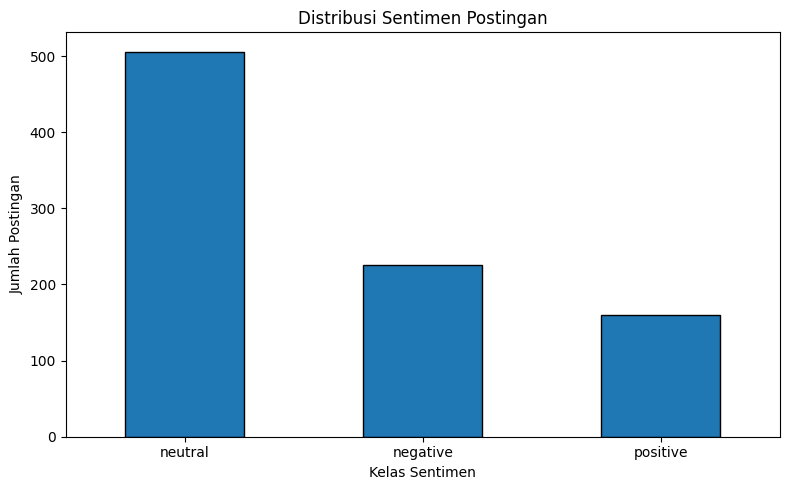

In [51]:
# GRAFIK DISTRIBUSI SENTIMEN

import matplotlib.pyplot as plt

# Menghitung jumlah tweet pada tiap kelas: positif, negatif, dan netral.
jumlah_sentimen = data['sentimen'].value_counts()

# Mengubah jumlah tersebut menjadi persentase dari seluruh data.
print("Persentase setiap sentimen:")
print(
    (data['sentimen'].value_counts(normalize=True) * 100)
    .round(2)
    .astype(str) + '%'
)

plt.figure(figsize=(8, 5))
# Membuat grafik batang untuk membandingkan jumlah tweet pada tiap kategori sentimen.
jumlah_sentimen.plot(kind='bar', edgecolor='black')

plt.title('Distribusi Sentimen Postingan')
plt.xlabel('Kelas Sentimen')
plt.ylabel('Jumlah Postingan')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [52]:
# MENYIAPKAN 20 SAMPEL EVALUASI MANUAL

# Mengambil maksimal 20 tweet secara acak.
sampel_manual = data[['text', 'cleaned_text']].sample(
    n=min(20, len(data)),random_state=42).copy()

# Menyimpan indeks asli untuk pencocokan prediksi
sampel_manual.insert(0, 'id_data', sampel_manual.index)

# Memberikan nomor sampel 1 sampai 20
sampel_manual = sampel_manual.reset_index(drop=True)
sampel_manual.insert(
    0, 'nomor', range(1, len(sampel_manual) + 1)
)

# Menampilkan teks tanpa prediksi sistem
display(sampel_manual[['nomor', 'text', 'cleaned_text']])



,nomor,text,cleaned_text
0,1,aku open joki essay makalah edit video convert...,aku open joki essay makalah edit video convert...
1,2,beneran masih speechless bgt kl pake chatgpt n...,beneran masih speechless bgt kl pake chatgpt n...
2,3,[cm]URGENT hai bantu isi kuesionerku plis butu...,cm urgent hai bantu isi kuesionerku plis butuh...
3,4,Joki Parafrase AI GPT ZERO Melayani Tugas Kuli...,joki parafrase ai gpt zero melayani tugas kuli...
4,5,kok dulu bisa ya aku kuliah sama sekali gak pa...,kok dulu bisa ya aku kuliah sama sekali gak pa...
5,6,chatgpt buat ngerjain tugas chatgpt buat bela ...,chatgpt buat ngerjain tugas chatgpt buat bela ...
6,7,jauhkan aku dari musibah chatGPT bocor,jauhkan aku dari musibah chatgpt bocor
7,8,@jebunggg riill even mereka dapet tugas buat r...,riill even mereka dapet tugas buat review jurn...
8,9,mau nanya dong sesama joki tugas apakah kalian...,mau nanya dong sesama joki tugas apakah kalian...
9,10,ChatGPTのAI執事とお話していて、ひとつとてもいいなと思ったのは、 「これについては事...,chatgptのai執事とお話していて ひとつとてもいいなと思ったのは これについては事実で...


In [53]:
3# MENGISI LABEL MANUAL UNTUK 20 SAMPEL

sampel_manual = sampel_manual.reset_index(drop=True)

# Menggabungkan kolom 'sentimen' dari dataframe utama 'data' agar tidak KeyError
if 'sentimen' not in sampel_manual.columns:
    sampel_manual = sampel_manual.merge(
        data[['text', 'cleaned_text', 'sentimen']],
        on=['text', 'cleaned_text'],
        how='left'
    )

# Membuat aturan input
label_pilihan = {
    '1': 'positive',
    '2': 'negative',
    '3': 'neutral'
}

# Meminta pengguna memasukkan label Jika input bukan 1, 2, atau 3, program meminta input ulang.
for i in range(len(sampel_manual)):
    print(f"\nSampel {i+1}")
    print("Teks:", sampel_manual.loc[i, 'cleaned_text'])
    print("Prediksi model:", sampel_manual.loc[i, 'sentimen'])

    print("\nPilih label manual:")
    print("1 = Positive")
    print("2 = Negative")
    print("3 = Neutral")

    while True:
        pilihan = input("Masukkan pilihan (1/2/3): ").strip()

        if pilihan in label_pilihan:
            sampel_manual.loc[i, 'label_manual'] = label_pilihan[pilihan]
            break

        print("Pilihan tidak valid. Masukkan 1, 2, atau 3.")

# Simpan hasil label manual
sampel_manual.to_csv(
    'evaluasi_sentimen.csv',
    index=False
)

print("\nSemua label manual berhasil disimpan!")
display(sampel_manual)


Sampel 1
Teks: aku open joki essay makalah edit video convert skripsi ke jurnal ppt infografis poster parafrase turnitin ai tugas kuliah maupun sekolah lainnya wa buat tanya tanya dulu boleh kok amanah dpt free revisi hasil pastinya on time terlebih harga bisa nego zonauang
Prediksi model: neutral

Pilih label manual:
1 = Positive
2 = Negative
3 = Neutral
Masukkan pilihan (1/2/3): 1

Sampel 2
Teks: beneran masih speechless bgt kl pake chatgpt ngebantu bgt kl lagi buntu kayak ni contohnya ngasih poin2 yg bisa ak jadiin bahan buat isi skripsi bjir kereeen bgt luuuh chatgpt kata ak teh ya allah semoga skripsi ini rampung tepat waktu tanpa ada rangkaian drama eah
Prediksi model: positive

Pilih label manual:
1 = Positive
2 = Negative
3 = Neutral
Masukkan pilihan (1/2/3): 1

Sampel 3
Teks: cm urgent hai bantu isi kuesionerku plis butuh 250 lagi isi ttg penggunaan gen ai mahasiswa chatgpt gemini dkk 3 5 menit aje syarat mahasiswa aktif min semester 3 pernah pakai gen ai mau barter ayok than

,nomor,id_data,text,cleaned_text,sentimen,label_manual
0,1,711,aku open joki essay makalah edit video convert...,aku open joki essay makalah edit video convert...,neutral,positive
1,2,440,beneran masih speechless bgt kl pake chatgpt n...,beneran masih speechless bgt kl pake chatgpt n...,positive,positive
2,3,846,[cm]URGENT hai bantu isi kuesionerku plis butu...,cm urgent hai bantu isi kuesionerku plis butuh...,neutral,neutral
3,4,723,Joki Parafrase AI GPT ZERO Melayani Tugas Kuli...,joki parafrase ai gpt zero melayani tugas kuli...,positive,neutral
4,5,40,kok dulu bisa ya aku kuliah sama sekali gak pa...,kok dulu bisa ya aku kuliah sama sekali gak pa...,negative,negative
5,6,291,chatgpt buat ngerjain tugas chatgpt buat bela ...,chatgpt buat ngerjain tugas chatgpt buat bela ...,negative,neutral
6,7,301,jauhkan aku dari musibah chatGPT bocor,jauhkan aku dari musibah chatgpt bocor,positive,negative
7,8,334,@jebunggg riill even mereka dapet tugas buat r...,riill even mereka dapet tugas buat review jurn...,negative,neutral
8,9,209,mau nanya dong sesama joki tugas apakah kalian...,mau nanya dong sesama joki tugas apakah kalian...,negative,neutral
9,10,137,ChatGPTのAI執事とお話していて、ひとつとてもいいなと思ったのは、 「これについては事...,chatgptのai執事とお話していて ひとつとてもいいなと思ったのは これについては事実で...,positive,neutral


In [54]:
# MEMBANDINGKAN LABEL MANUAL DENGAN PREDIKSI MODEL

# Memastikan semua label sudah terisi
if sampel_manual['label_manual'].isna().any() or (
    sampel_manual['label_manual'].astype(str).str.strip() == ''
).any():
    raise ValueError("Masih ada label manual yang kosong!")

# Membandingkan label_manual dengan sentimen dari model.
# Jika sama, nilainya True; jika berbeda, nilainya False.
sampel_manual['sesuai'] = (
    sampel_manual['label_manual'].str.lower().str.strip()
    == sampel_manual['sentimen'].str.lower().str.strip()
)

jumlah_sampel = len(sampel_manual)
jumlah_sesuai = int(sampel_manual['sesuai'].sum())
jumlah_tidak_sesuai = jumlah_sampel - jumlah_sesuai
persentase = jumlah_sesuai / jumlah_sampel * 100

print("Jumlah sampel:", jumlah_sampel)
print("Jumlah label yang sesuai:", jumlah_sesuai)
print("Jumlah label yang tidak sesuai:", jumlah_tidak_sesuai)
print(f"Persentase kesesuaian: {persentase:.2f}%")

display(sampel_manual[
    ['cleaned_text', 'label_manual', 'sentimen', 'sesuai']
])


Jumlah sampel: 20
Jumlah label yang sesuai: 9
Jumlah label yang tidak sesuai: 11
Persentase kesesuaian: 45.00%


,cleaned_text,label_manual,sentimen,sesuai
0,aku open joki essay makalah edit video convert...,positive,neutral,False
1,beneran masih speechless bgt kl pake chatgpt n...,positive,positive,True
2,cm urgent hai bantu isi kuesionerku plis butuh...,neutral,neutral,True
3,joki parafrase ai gpt zero melayani tugas kuli...,neutral,positive,False
4,kok dulu bisa ya aku kuliah sama sekali gak pa...,negative,negative,True
5,chatgpt buat ngerjain tugas chatgpt buat bela ...,neutral,negative,False
6,jauhkan aku dari musibah chatgpt bocor,negative,positive,False
7,riill even mereka dapet tugas buat review jurn...,neutral,negative,False
8,mau nanya dong sesama joki tugas apakah kalian...,neutral,negative,False
9,chatgptのai執事とお話していて ひとつとてもいいなと思ったのは これについては事実で...,neutral,positive,False


In [55]:
# MENAMPILKAN MAKSIMAL 3 KETIDAKSESUAIAN

# Memilih data yang hasil modelnya tidak sama dengan label manual dengan membatasi tampilan menjadi 3 contoh pertama
ketidaksesuaian = sampel_manual[
    sampel_manual['sesuai'] == False].head(3)
# Mengecek apakah ada ketidaksesuaian. Jika tidak ada, program menampilkan pesan bahwa semua prediksi sesuai.
if ketidaksesuaian.empty:
    print("Tidak ditemukan ketidaksesuaian.")
else:
    print("Contoh ketidaksesuaian (maksimal 3):")
    display(ketidaksesuaian[
        ['cleaned_text', 'label_manual', 'sentimen']
    ])


Contoh ketidaksesuaian (maksimal 3):


,cleaned_text,label_manual,sentimen
0,aku open joki essay makalah edit video convert...,positive,neutral
3,joki parafrase ai gpt zero melayani tugas kuli...,neutral,positive
5,chatgpt buat ngerjain tugas chatgpt buat bela ...,neutral,negative


In [56]:
# MENYIMPAN HASIL ANALISIS SENTIMEN
data[['text', 'cleaned_text', 'sentimen']].to_csv(
    'hasil_analisis_sentimen.csv',
    index=False,
    encoding='utf-8-sig'
)

# MENYIMPAN HASIL EVALUASI MANUAL
sampel_manual.to_csv(
    'hasil_evaluasi_sentimen.csv',
    index=False,
    encoding='utf-8-sig'
)

print("Kedua file berhasil disimpan!")



Kedua file berhasil disimpan!


**REGRESI** **LINEAR**

In [57]:
# CREATE A MODEL

import pandas as pd
import re
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

# Menggunakan data hasil cleaning sebelumnya
df_model = data.copy()

print("Jumlah data:", len(df_model))
print("Kolom dataset:")
print(df_model.columns.tolist())

Jumlah data: 891
Kolom dataset:
['conversation_id_str', 'created_at', 'favorite_count', 'full_text', 'id_str', 'image_url', 'in_reply_to_screen_name', 'lang', 'location', 'quote_count', 'reply_count', 'retweet_count', 'tweet_url', 'user_id_str', 'username', 'text', 'like_count', 'cleaned_text', 'word_count', 'hashtag_count', 'cluster', 'sentimen']


In [58]:
# Menghitung kata dan hashtag dari teks asli
data['word_count'] = (
    data['text'].fillna('').astype(str)
    .apply(lambda teks: len(teks.split()))
)

data['hashtag_count'] = (
    data['text'].fillna('').astype(str)
    .apply(lambda teks: teks.count('#'))
)

print("Penghitungan kata dan hashtag selesai!")


Penghitungan kata dan hashtag selesai!


In [59]:
# MENYIAPKAN DATA MODEL

# Mengambil fitur dan target yang dibutuhkan
df_model = data[
    ['word_count', 'hashtag_count', 'like_count']
].copy()

# Memastikan semua kolom numerik
for kolom in ['word_count', 'hashtag_count', 'like_count']:
    df_model[kolom] = pd.to_numeric(
        df_model[kolom], errors='coerce'
    )

# Menghapus data dengan fitur atau target kosong
df_model = df_model.dropna(
    subset=['word_count', 'hashtag_count', 'like_count']
)

# Menghapus nilai tidak valid
df_model = df_model[
    (df_model['word_count'] >= 0) &
    (df_model['hashtag_count'] >= 0) &
    (df_model['like_count'] >= 0)
]

# Menampilkan hasil
print("Jumlah data untuk regresi:", len(df_model))
display(df_model.head())

Jumlah data untuk regresi: 891


,word_count,hashtag_count,like_count
0,41,0,22
1,23,1,2
2,42,0,80
3,24,0,0
4,7,0,1


In [60]:
# FITUR, TARGET, DAN PEMBAGIAN DATA

X = df_model[['word_count', 'hashtag_count']]
y = df_model['like_count']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Jumlah data latih:", len(X_train))
print("Jumlah data uji:", len(X_test))


Jumlah data latih: 712
Jumlah data uji: 179


In [61]:
# MEMBUAT DAN MELATIH MODEL

model = LinearRegression()
model.fit(X_train, y_train)

print("Model regresi linear berhasil dilatih!")


Model regresi linear berhasil dilatih!


In [62]:
# EVALUASI MODEL

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 2))
print("R² Score:", round(r2, 4))


MAE: 2365.2
R² Score: -0.0142


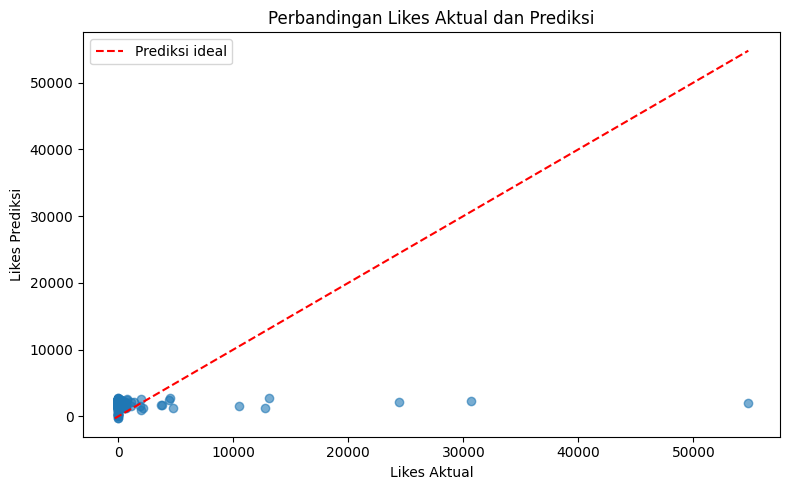

In [63]:
# VISUALISASI HASIL

plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.6)

plt.xlabel("Likes Aktual")
plt.ylabel("Likes Prediksi")
plt.title("Perbandingan Likes Aktual dan Prediksi")

batas_min = min(y_test.min(), y_pred.min())
batas_max = max(y_test.max(), y_pred.max())

plt.plot(
    [batas_min, batas_max],
    [batas_min, batas_max],
    'r--',
    label='Prediksi ideal'
)

plt.legend()
plt.tight_layout()
plt.show()


In [64]:

# IMPORT LIBRARY UNTUK MEMBUAT FORMULIR INTERAKTIF
import ipywidgets as widgets
from IPython.display import display, clear_output

# MEMBUAT INPUT JUMLAH KATA
input_kata = widgets.IntText(
    value=30,
    description='Jumlah kata:'
)

# MEMBUAT INPUT JUMLAH HASHTAG
input_hashtag = widgets.IntText(
    value=2,
    description='Jumlah hashtag:'
)

# MEMBUAT TOMBOL DAN AREA HASIL
tombol = widgets.Button(description='Estimasi Likes')
hasil = widgets.Output()

# MEMBUAT FUNGSI UNTUK MENGHITUNG ESTIMASI LIKES
def estimasi_likes(b):
    with hasil:
        # MEMBERSIHKAN HASIL SEBELUMNYA
        clear_output()

        # MEMERIKSA AGAR INPUT TIDAK BERNILAI NEGATIF
        if input_kata.value < 0 or input_hashtag.value < 0:
            print("Jumlah kata dan hashtag tidak boleh negatif.")
            return

        # MENYIAPKAN DATA BARU SESUAI FITUR MODEL
        data_baru = pd.DataFrame({
            'word_count': [input_kata.value],
            'hashtag_count': [input_hashtag.value]
        })

        # MELAKUKAN PREDIKSI MENGGUNAKAN MODEL REGRESI LINEAR
        prediksi = model.predict(data_baru)[0]

        # MENAMPILKAN HASIL ESTIMASI LIKES
        print("Estimasi likes:", round(prediksi, 2))

        # MEMBERIKAN PERINGATAN JIKA PREDIKSI NEGATIF
        if prediksi < 0:
            print(
                "Estimasi negatif tidak bermakna sebagai jumlah likes "
                "dan menunjukkan keterbatasan model."
            )

# MENGHUBUNGKAN TOMBOL DENGAN FUNGSI PREDIKSI
tombol.on_click(estimasi_likes)

# MENAMPILKAN FORMULIR INPUT DAN HASIL
display(input_kata, input_hashtag, tombol, hasil)




IntText(value=30, description='Jumlah kata:')

IntText(value=2, description='Jumlah hashtag:')

Button(description='Estimasi Likes', style=ButtonStyle())

Output()

In [65]:
import os
import joblib

# Membuat direktori 'model' jika belum ada
os.makedirs('model', exist_ok=True)

# Menyimpan model regresi linear yang ada di variabel 'model'
path_model = 'model/model_lr.joblib'
joblib.dump(model, path_model)

print(f"Model regresi linear berhasil disimpan di: {path_model}")

Model regresi linear berhasil disimpan di: model/model_lr.joblib
